# Beginning

In [1]:
# Все библиотеки

import numpy as np
import pandas as pd
import scipy.stats as stats
from numba.cuda import defer_cleanup
from scipy.stats import ttest_ind, levene, mannwhitneyu,shapiro, \
    f_oneway, kruskal, chi2_contingency, fisher_exact
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import scikit_posthocs as sp
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import pingouin as pg
import sys
import os
from ydata_profiling import ProfileReport
from matplotlib import rcParams
from matplotlib import font_manager as fm
import matplotlib as mpl
import warnings

mpl.rcParams['font.family'] = 'HSE Sans'
plt.rcParams['figure.dpi'] = 300

warnings.filterwarnings('ignore')

import graphics
import tests

/Users/ssd/Documents/src/dano_base/base/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
df = pd.read_excel("База Нижний Новгород.xlsx")
df.columns = df.columns.str.replace(" ", "_")
df.head(5)

,id,year,gender,faculty,teaching_position,position_head,HSE_start,experience_uni,bachelor,specialist,...,courses_master,courses_minor,courses_magolego,courses_elective,thesis_bachelor,thesis_master,PhD_students,PhD_finished,best_teacher,best_teacher_previous
0,100,y24_25,M,econ,профессор,1,1998,27.0,NaN,1998,...,1,0,1,0,3,2,2,8,0,6
1,100,y23_24,M,econ,профессор,1,1998,26.0,NaN,1998,...,1,0,1,0,5,0,2,8,0,6
2,100,y22_23,M,econ,профессор,1,1998,25.0,NaN,1998,...,1,0,1,0,0,4,1,8,0,6
3,101,y24_25,M,econ,доцент,1,2006,14.0,2005,NaN,...,0,0,0,0,0,0,1,0,0,2
4,101,y23_24,M,econ,доцент,1,2006,13.0,2005,NaN,...,0,0,0,0,0,0,1,0,0,2


In [ ]:
profile = ProfileReport(df, title="Profiling Report", correlations={
            "auto": {"calculate": True},
            "pearson": {"calculate": True},
            "spearman": {"calculate": True},
            "kendall": {"calculate": True},
            "phi_k": {"calculate": True},
            "cramers": {"calculate": True},
        },)
profile.to_file("your_report.html")

In [3]:
df.select_dtypes(include=[np.number]).groupby(by='best_teacher').mean()

,id,position_head,HSE_start,experience_uni,HSE_graduate,publications_papers,publications_other,publications_papers_3years,publications_other_3years,publications_papers_5years,...,courses_bachelor,courses_master,courses_minor,courses_magolego,courses_elective,thesis_bachelor,thesis_master,PhD_students,PhD_finished,best_teacher_previous
best_teacher,,,,,,,,,,,,,,,,,,,,,
0,512.589719,0.210960,2014.562561,20.295918,0.284190,1.121726,0.566925,3.405917,1.994665,5.583414,...,1.776431,0.833172,0.219690,0.596993,0.034918,0.964597,0.644520,0.270611,0.348206,0.900582
1,520.842353,0.268235,2012.887059,18.781163,0.350588,1.218824,0.736471,3.524706,2.560000,5.950588,...,2.630588,1.395294,0.374118,1.014118,0.063529,1.750588,1.343529,0.461176,0.298824,3.331765


In [42]:
df[((df['experience_uni'] >= 1) | (df['experience_uni'].isna()))]['best_teacher'].mean()

np.float64(0.173053152039555)

<Axes: >

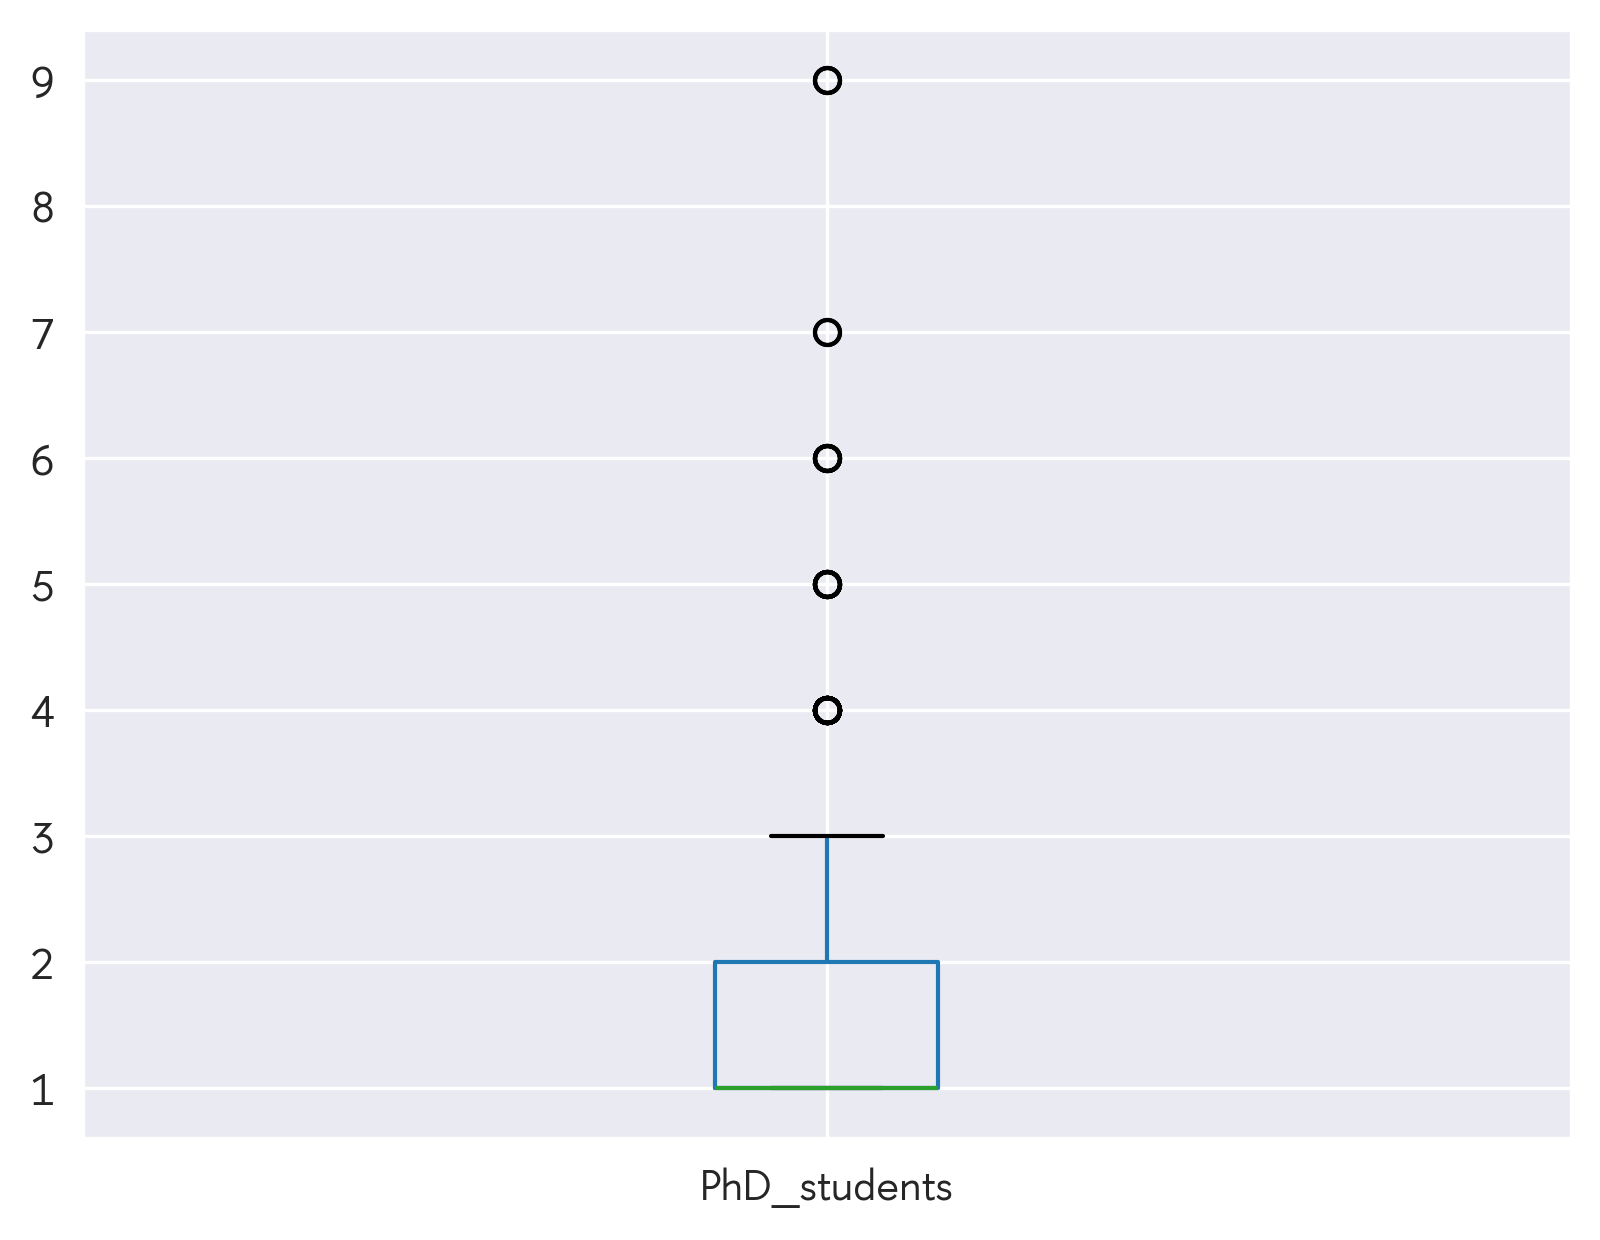

In [17]:
df[df['PhD_students'] > 0][['PhD_students']].boxplot()
#TODO: тыкнуть зенова скинуть графики

In [22]:
df[df['thesis_bachelor'] > 0][['thesis_bachelor']].boxplot()

<Axes: >

In [ ]:
df[df['thesis_master'] > 0][['thesis_master']].boxplot()

In [24]:
from sklearn.preprocessing import StandardScaler

supervision_cols = ['thesis_bachelor', 'thesis_master', 'PhD_students']
df_cleared = df[(df['thesis_bachelor'] <= 8) & (df['thesis_master'] <= 6) & (df['PhD_students'] <= 3) & ((df['experience_uni'] >= 1) | (df['experience_uni'].isna()))].copy()

scaler = StandardScaler()
supervision_scaled = scaler.fit_transform(df_cleared[supervision_cols])

df_cleared['supervision_factor'] = supervision_scaled.sum(axis=1)

In [25]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df_cleared['supervision_factor_0_1'] = scaler.fit_transform(df_cleared[['supervision_factor']])

print("Результат Min-Max Scaling:")
print(df_cleared['supervision_factor_0_1'].describe())

Результат Min-Max Scaling:
count    2268.000000
mean        0.095512
std         0.156678
min         0.000000
25%         0.000000
50%         0.000000
75%         0.141181
max         1.000000
Name: supervision_factor_0_1, dtype: float64


In [40]:
cols = list(df_cleared.columns)
agg_dict = {c: 'first' for c in cols if (c != 'HSE_graduate')}
agg_dict['HSE_graduate'] = 'max'
df_uniq = df_cleared.groupby('id', as_index=False).agg(agg_dict)

In [35]:
def anton(x):
    if x['year'] == 'y22_23':
        return -1
    elif x['year'] == 'y23_24':
        if len(df[(df['id'] == x['id']) & (df['year'] == 'y22_23')]['best_teacher'].tolist()) == 0:
            return -1
        return df[(df['id'] == x['id']) & (df['year'] == 'y22_23')]['best_teacher'].tolist()[0]
    else:
        if len(df[(df['id'] == x['id']) & (df['year'] == 'y23_24')]['best_teacher'].tolist()) == 0:
            return -1
        return df[(df['id'] == x['id']) & (df['year'] == 'y23_24')]['best_teacher'].tolist()[0]


df_cleared['flag_prev_year_best'] = df_cleared.apply(lambda x: anton(x), axis=1)
df_cleared[df_cleared['flag_prev_year_best'] != -1][['flag_prev_year_best', 'supervision_factor_0_1']]

,flag_prev_year_best,supervision_factor_0_1
0,0,0.542664
1,0,0.499709
3,0,0.127072
4,0,0.127072
6,1,0.147339
...,...,...
2479,0,0.000000
2481,0,0.070590
2482,0,0.070590
2484,0,0.049113


In [36]:
df_cleared[df_cleared['flag_prev_year_best'] != -1][['flag_prev_year_best', 'best_teacher']]

,flag_prev_year_best,best_teacher
0,0,0
1,0,0
3,0,0
4,0,0
6,1,0
...,...,...
2479,0,0
2481,0,0
2482,0,0
2484,0,0


# Гипотеза + Проверка

In [51]:
from scipy.stats import mannwhitneyu

def analyze_correlation(df, continuous_var, binary_var):
    group_0 = df[df[binary_var] == 0][continuous_var]
    group_1 = df[df[binary_var] == 1][continuous_var]

    u_stat, p_mannwhitney = mannwhitneyu(group_0, group_1, alternative='two-sided')
    print(f"Тест Манна-Уитни: U = {u_stat:.4f}, p = {p_mannwhitney:.4f}")
    print(f"Стат. значимо (p < 0.05): {'YEAS' if p_mannwhitney < 0.05 else 'NO'}")
    print()

    #TODO: тыкнуть зенова скинуть графики

analyze_correlation(df_cleared, 'supervision_factor', 'best_teacher')

Тест Манна-Уитни: U = 277832.0000, p = 0.0000
Стат. значимо (p < 0.05): YEAS



In [56]:

def analyze_faculty_groups(df, faculty_col='faculty', target_col='supervision_factor_0_1', group_col='best_teacher'):
    faculties = df[faculty_col].unique()

    for faculty in faculties:
        faculty_data = df[df[faculty_col] == faculty]

        group_0 = faculty_data[faculty_data[group_col] == 0][target_col].dropna()
        group_1 = faculty_data[faculty_data[group_col] == 1][target_col].dropna()

        u_stat, u_p = mannwhitneyu(group_0, group_1, alternative='two-sided')
        n0, n1 = len(group_0), len(group_1)
        r_effect = u_stat / (n0 * n1)
        print(f"\nФакультет: {faculty}")
        print(f"  Наблюдения: всего={len(faculty_data)}, best_teacher=0={len(group_0)}, best_teacher=1={len(group_1)}")
        print(f"  Медианы: 0={group_0.median():.4f}, 1={group_1.median():.4f}")
        print(f"  Манна-Уитни: U={u_stat:.4f}, p={u_p:.4f} {'YES' if u_p < 0.05 else 'NO'}")
        print(f"  Размер эффекта: {r_effect:.4f}")

analyze_faculty_groups(df_cleared)
analyze_faculty_groups(df_cleared, faculty_col='HSE_graduate')
analyze_faculty_groups(df_cleared, faculty_col='gender')


Факультет: econ
  Наблюдения: всего=740, best_teacher=0=625, best_teacher=1=115
  Медианы: 0=0.0000, 1=0.0491
  Манна-Уитни: U=31897.5000, p=0.0353 YES
  Размер эффекта: 0.4438

Факультет: human
  Наблюдения: всего=1229, best_teacher=0=1005, best_teacher=1=224
  Медианы: 0=0.0000, 1=0.0844
  Манна-Уитни: U=80121.5000, p=0.0000 YES
  Размер эффекта: 0.3559

Факультет: math
  Наблюдения: всего=299, best_teacher=0=263, best_teacher=1=36
  Медианы: 0=0.0491, 1=0.1271
  Манна-Уитни: U=3688.5000, p=0.0247 YES
  Размер эффекта: 0.3896

Факультет: 1
  Наблюдения: всего=660, best_teacher=0=526, best_teacher=1=134
  Медианы: 0=0.0000, 1=0.0000
  Манна-Уитни: U=30159.5000, p=0.0026 YES
  Размер эффекта: 0.4279

Факультет: 0
  Наблюдения: всего=1608, best_teacher=0=1367, best_teacher=1=241
  Медианы: 0=0.0000, 1=0.0982
  Манна-Уитни: U=120443.0000, p=0.0000 YES
  Размер эффекта: 0.3656

Факультет: M
  Наблюдения: всего=1215, best_teacher=0=1004, best_teacher=1=211
  Медианы: 0=0.0000, 1=0.0706
  

# Графики

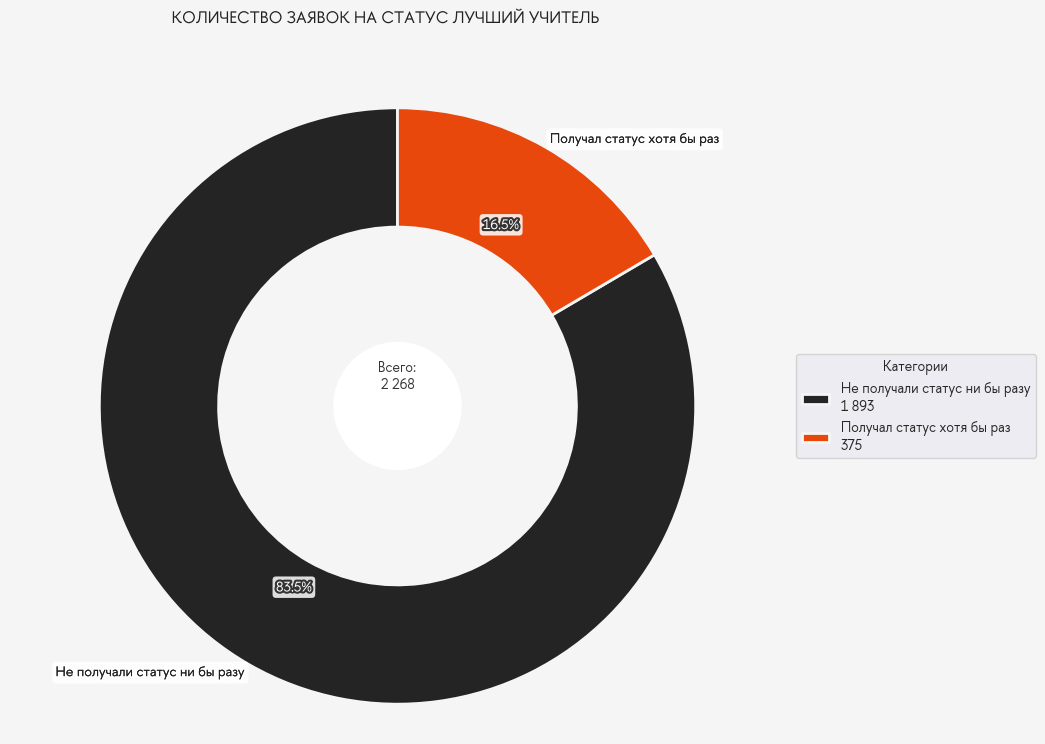

In [43]:
from matplotlib.font_manager import FontProperties, fontManager
import matplotlib.patheffects as path_effects



def _fmt_int(n: int) -> str:
    """Форматирование числа с пробелами между тысячами."""
    return f"{n:,}".replace(",", " ")

# --- Палитра в твоих цветах ---
MAIN2 = "#e9480d"  # светлый серо-зелёный
MAIN1 = "#242424"  # тёмная фуксия

def _hex_to_rgb01(h):
    h = h.lstrip('#')
    return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)]) / 255.0

def _rgb01_to_hex(rgb):
    rgb = np.clip(rgb, 0, 1)
    return '#' + ''.join(f'{int(round(c*255)):02X}' for c in rgb)

def _lighten(hex_color, t=0.25):
    """Осветлить цвет, смешав с белым на t (0..1)."""
    return _rgb01_to_hex(_hex_to_rgb01(hex_color) * (1 - t) + t)

def _build_palette(n):
    """Возвращает n цветов, начиная с MAIN1, MAIN2 и мягких оттенков."""
    if n <= 2:
        return [MAIN1, MAIN2][:n]
    extras = []
    for i, t in enumerate([0.18, 0.32, 0.46, 0.60, 0.72, 0.84]):
        extras.append(_lighten(MAIN1 if i % 2 == 0 else MAIN2, t))
    return ([MAIN1, MAIN2] + extras)[:n]
# --------------------------------

def fancy_pie_chart(values, labels, total=None, colors=None,
                    title="Круговая диаграмма", filename=None):
    """
    Кольцевая диаграмма с HSE Sans (Regular) и защитой от наезда подписей на заголовок.
    """
    if total is None:
        total = sum(values)
    percentages = [100 * v / total for v in values]

    # Палитра по умолчанию — твои цвета
    if colors is None:
        colors = _build_palette(len(values))

    edge_color = '#F5F5F5'

    # Больше воздуха сверху — диаграмма ниже заголовка
    fig, ax = plt.subplots(figsize=(10, 8), dpi=100, facecolor='#F5F5F5')
    fig.subplots_adjust(top=0.90, bottom=0.08)

    wedges, texts, autotexts = ax.pie(
        percentages,
        labels=labels,
        colors=colors,
        startangle=90,
        radius=1.0,
        wedgeprops=dict(width=0.4, edgecolor=edge_color, linewidth=2),
        textprops=dict(
            color='#222222',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.85, edgecolor='none')
        ),
        autopct='%1.1f%%',
        pctdistance=0.70,   # проценты ближе к центру
        labeldistance=1.03  # подписи ближе к кольцу, чтобы не задевали заголовок
    )

    # Обводка/тень у названий сегментов
    for txt in texts:
        txt.set_path_effects([
            path_effects.withStroke(linewidth=2.5, foreground='white'),
            path_effects.SimpleLineShadow(offset=(1, -1), alpha=0.4),
            path_effects.Normal()
        ])

    # Доп. сдвиг подписей в верхней зоне (70–110°)
    for w, txt in zip(wedges, texts):
        ang = 0.5 * (w.theta1 + w.theta2)  # средний угол сегмента
        if 70 <= ang <= 110:
            x, y = txt.get_position()
            txt.set_position((x, y - 0.12))  # слегка опускаем подпись

    # Стилизация процентов
    for autotext in autotexts:
        autotext.set_color('white')
        autotext.set_path_effects([path_effects.withStroke(linewidth=3, foreground='#333333')])

    # Центральный круг
    centre_circle = plt.Circle((0, 0), 0.22, color=edge_color, fc='white', linewidth=2)
    ax.add_artist(centre_circle)

    # Подписи в центре
    ax.text(
        0, 0.1, f"Всего:\n{_fmt_int(total)}",
        ha='center', va='center',
        color='#333333'
    )

    # Заголовок (крупный, но не bold)
    title_obj = fig.suptitle(title, color='#222222', y=0.985)
    title_obj.set_path_effects([
        path_effects.SimpleLineShadow(offset=(0, -1), alpha=0.35),
        path_effects.Normal()
    ])

    # Легенда
    legend_labels = [f'{label}\n{_fmt_int(val)}' for label, val in zip(labels, values)]
    ax.legend(
        wedges, legend_labels, title="Категории", loc="center left",
        bbox_to_anchor=(1, 0, 0.55, 1), borderaxespad=0.8
    )

    ax.axis('equal')

    if filename:
        plt.savefig(filename, bbox_inches='tight', dpi=300, transparent=False)

    plt.show()

values = [1893, 375]
labels = ["Не получали статус ни бы разу", "Получал статус хотя бы раз"]

fancy_pie_chart(
    values, labels, total= 2268,
    title= "КОЛИЧЕСТВО ЗАЯВОК НА СТАТУС ЛУЧШИЙ УЧИТЕЛЬ",
    filename="call_success_rate_pie_chart.png"
)


In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.font_manager import FontProperties, fontManager

# === Цвета ===
ORANGE = "#e9480d"      # более яркий оранжевый
BLACK = "#111111"
GRAY_BORDER = "#D9D9D9"

# === Шрифт HSE Sans ===
FONT_DIR = r"C:\Users\coldn\Downloads\HSE Sans"

def _resolve_font(*names):
    for name in names:
        path = os.path.join(FONT_DIR, name)
        if os.path.exists(path):
            return path
    raise FileNotFoundError("Не найден файл HSE Sans. Проверь FONT_DIR.")


# === Функция для boxplot ===
def plot_box_hse(
        df,
        col,
        title=None,
        xlabel=None,
        ylabel="Значение",
        savepath=None
):
    """Boxplot в оранжево-чёрном стиле HSE: яркий акцент, белый фон, тонкие рамки."""
    fig, ax = plt.subplots(figsize=(6, 5), dpi=100, facecolor="white")

    sns.boxplot(
        data=df,
        y=col,
        color=ORANGE,
        width=0.35,             # уже, чем стандартный boxplot
        fliersize=7,
        linewidth=1.5,
        boxprops=dict(facecolor=ORANGE, edgecolor=BLACK, linewidth=1.4),
        medianprops=dict(color=BLACK, linewidth=2),
        whiskerprops=dict(color=BLACK, linewidth=1.1),
        capprops=dict(color=BLACK, linewidth=1.1),
        ax=ax
    )

    # --- Оформление ---
    ax.set_facecolor("white")
    for spine in ax.spines.values():
        spine.set_edgecolor(GRAY_BORDER)
        spine.set_linewidth(0.8)

    ax.grid(False)
    ax.tick_params(colors=BLACK)
    ax.set_xlabel(xlabel if xlabel else "", size=14, color=BLACK, labelpad=8)
    ax.set_ylabel(ylabel, size=14, color=BLACK, labelpad=8)
    ax.set_title(title or f"Распределение {col}", size=20, color=BLACK, pad=15)

    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, bbox_inches="tight", dpi=300)
        print(f"Сохранено в {savepath}")
    plt.show()


Сохранено в box_supervision.png


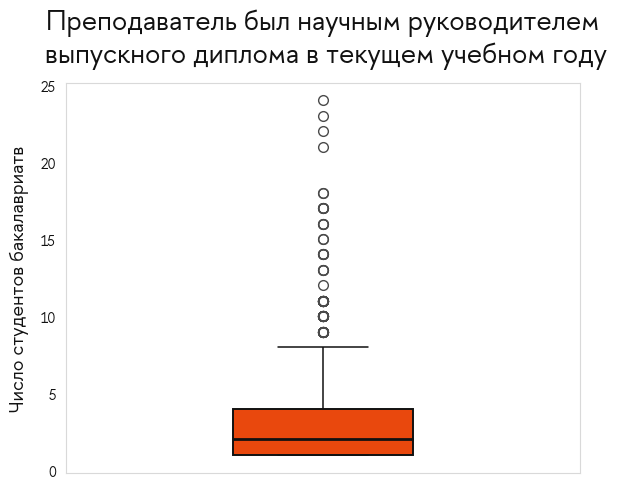

In [46]:
plot_box_hse(
    df[df["thesis_bachelor"] > 0],
    col="thesis_bachelor",
    title="Преподаватель был научным руководителем\n выпускного диплома в текущем учебном году",
    ylabel="Число студентов бакалавриатв",
    savepath="box_supervision.png"
)


Сохранено в box_supervision_asp.png


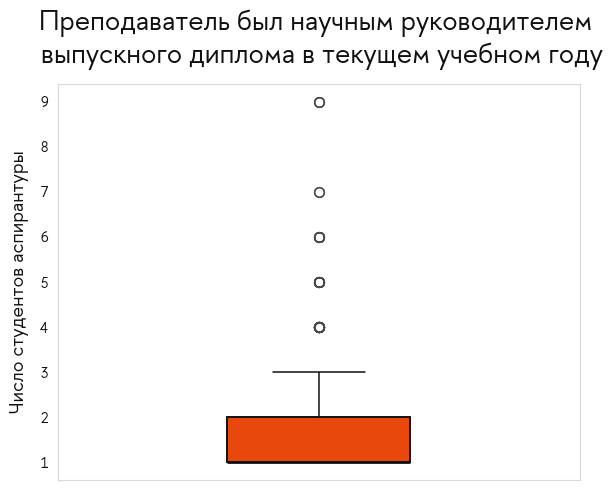

In [47]:
plot_box_hse(
    df[df["PhD_students"] > 0],
    col="PhD_students",
    title="Преподаватель был научным руководителем \n выпускного диплома в текущем учебном году",
    ylabel="Число студентов аспирантуры",
    savepath="box_supervision_asp.png"
)


Сохранено в box_supervision_mag.png


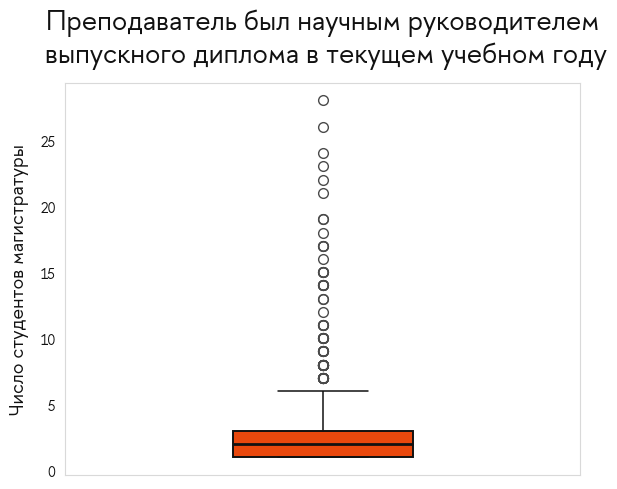

In [48]:
plot_box_hse(
    df[df["thesis_master"] > 0],
    col="thesis_master",
    title="Преподаватель был научным руководителем\n "
          "выпускного диплома в текущем учебном году",
    ylabel="Число студентов магистратуры",
    savepath="box_supervision_mag.png"
)


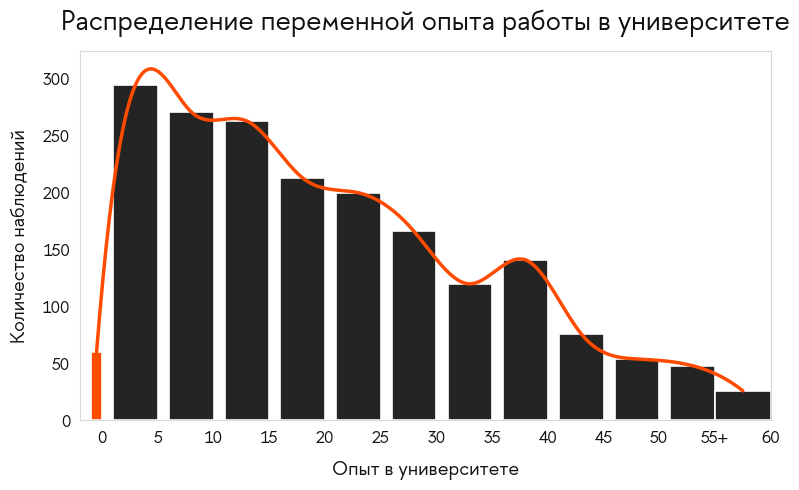

In [50]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.font_manager import FontProperties, fontManager
from scipy.interpolate import make_interp_spline  # гладкая линия

# === Цвета ===
ORANGE = "#ff4b00"
BLACK  = "#111111"
GRAY_BORDER = "#D9D9D9"
DARK = "#242424"

# === Шрифт HSE Sans ===
FONT_DIR = r"C:\Users\coldn\Downloads\HSE Sans"

def _resolve_font(*names):
    for name in names:
        path = os.path.join(FONT_DIR, name)
        if os.path.exists(path):
            return path
    raise FileNotFoundError("Не найден файл HSE Sans. Проверь FONT_DIR.")

# --- данные ---
s = df["experience_uni"].dropna()

# --- интервалы: [-1,0], [1,5], [6,10], ..., [51,55], [55+]
ranges = [(-1, 0), (1, 5)] + [(a, a+4) for a in range(6, 56, 5)]  # до (51,55)
plot_last_right = 60  # для аккуратной геометрии на оси

counts, left_edges, right_edges = [], [], []

# все обычные интервалы
for L, R in ranges:
    cnt = ((s >= L) & (s <= R)).sum()
    counts.append(int(cnt))
    left_edges.append(L)
    right_edges.append(R)

# последний "55+"
cnt_last = (s >= 55).sum()
counts.append(int(cnt_last))
left_edges.append(55)
right_edges.append(plot_last_right)  # рисуем ширину 5

counts = np.array(counts, float)
left_edges = np.array(left_edges, float)
right_edges = np.array(right_edges, float)
widths = right_edges - left_edges
centers = left_edges + widths/2

# --- график ---
fig, ax = plt.subplots(figsize=(8, 5), dpi=100, facecolor="white")

# цвета: только [-1,0] оранжевый, всё остальное тёмное
colors = [ORANGE] + [DARK]*(len(counts)-1)

for L, w, h, c in zip(left_edges, widths, counts, colors):
    ax.bar(L, h, width=w, align="edge",
           color=c, edgecolor="white", linewidth=1.2)

# --- гладкая оранжевая линия по верхам столбцов ---
x_smooth = np.linspace(centers.min(), centers.max(), 400)
y_smooth = make_interp_spline(centers, counts, k=3)(x_smooth)
ax.plot(x_smooth, y_smooth, color=ORANGE, linewidth=2.5)

# --- оформление ---
ax.set_facecolor("white")
for spine in ax.spines.values():
    spine.set_edgecolor(GRAY_BORDER)
    spine.set_linewidth(0.8)

ax.grid(False)
ax.set_xlim(-2, 60)
ax.set_xticks(np.arange(0, 61, 5))
ax.set_xticklabels(
    [("55+" if x==55 else str(int(x))) for x in np.arange(0, 61, 5)], size=12, color=BLACK
)

ax.set_xlabel("Опыт в университете", size=14, color=BLACK, labelpad=10)
ax.set_ylabel("Количество наблюдений", size=14, color=BLACK, labelpad=10)
ax.set_title("Распределение переменной опыта работы в университете", size=20, color=BLACK, pad=15)

ax.tick_params(colors=BLACK, labelsize=12)

plt.tight_layout()
plt.savefig("experience_uni_distribution_55plus.png", bbox_inches="tight", dpi=300)
plt.show()

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
from matplotlib.font_manager import FontProperties, fontManager

# === Цвета ===
ORANGE = "#ff4b00"      # яркий оранжевый
BLACK  = "#111111"
GRAY_FILL = "#242424"   # мягкий серый для второго KDE
GRAY_BORDER = "#D9D9D9" # рамки

# === Шрифт HSE Sans ===
FONT_DIR = r"C:\Users\coldn\Downloads\HSE Sans"

def _resolve_font(*names):
    for name in names:
        path = os.path.join(FONT_DIR, name)
        if os.path.exists(path):
            return path
    raise FileNotFoundError("Не найден файл HSE Sans. Проверь FONT_DIR.")

regular_font_path = _resolve_font("HSESans-Regular.otf", "HSESans-Regular.ttf")
fontManager.addfont(regular_font_path)
font_prop = FontProperties(fname=regular_font_path)

def plot_kde_two(
        s1, s2,
        label1="Датасет 1", label2="Датасет 2",
        title="Распределение (KDE)",
        xlabel="Значение",
        ylabel="Плотность распределения",
        bw_method="scott",
        clip=None,
        savepath=None
):
    """Две KDE на одном графике: оранжевая линия + серая заливка."""
    x1 = np.asarray(s1, dtype=float)
    x2 = np.asarray(s2, dtype=float)
    x1 = x1[~np.isnan(x1)]
    x2 = x2[~np.isnan(x2)]

    if clip is None and (x1.size or x2.size):
        xmin = np.nanmin([x1.min() if x1.size else np.inf,
                          x2.min() if x2.size else np.inf])
        xmax = np.nanmax([x1.max() if x1.size else -np.inf,
                          x2.max() if x2.size else -np.inf])
        clip = (xmin, xmax)

    fig, ax = plt.subplots(figsize=(8, 5), dpi=100, facecolor="white")

    # Второй датасет — серая заливка
    if x2.size:
        sns.kdeplot(
            x=x2,
            fill=True, color=GRAY_FILL, alpha=0.6,
            linewidth=0,
            clip=clip, bw_method=bw_method,
            ax=ax, label=label2
        )

    # Первый датасет — оранжевая линия с прозрачной заливкой
    if x1.size:
        sns.kdeplot(
            x=x1,
            fill=True, color=ORANGE, alpha=0.25,
            linewidth=2, clip=clip, bw_method=bw_method,
            ax=ax
        )
        sns.kdeplot(
            x=x1,
            fill=False, color=ORANGE,
            linewidth=2.3, clip=clip, bw_method=bw_method,
            ax=ax, label=label1
        )

    # --- Оформление ---
    ax.set_facecolor("white")
    for spine in ax.spines.values():
        spine.set_edgecolor(GRAY_BORDER)
        spine.set_linewidth(0.8)

    ax.grid(False)
    ax.tick_params(colors=BLACK)

    ax.set_title(title, fontproperties=font_prop, size=20, color=BLACK, pad=15)
    ax.set_xlabel(xlabel, fontproperties=font_prop, size=14, color=BLACK)
    ax.set_ylabel(ylabel, fontproperties=font_prop, size=14, color=BLACK)

    leg = ax.legend(frameon=False, prop=font_prop)
    for txt in leg.get_texts():
        txt.set_color(BLACK)

    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, bbox_inches="tight", dpi=300)
        print(f"Сохранено в {savepath}")
    plt.show()
s_grad = df_cleared.loc[df_cleared["best_teacher"]==1, "supervision_factor_0_1"]
s_nograd = df_cleared.loc[df_cleared["best_teacher"]==0, "supervision_factor_0_1"]

plot_kde_two(
    s_grad, s_nograd,
    label1="Получали награду лучший учитель",
    label2="Не получали",
    title="Получившие награду преподаватели обладают \n большей вовлеченностью",
    xlabel="Вовлеченность",
    ylabel="Плотность",
    clip=(0, 1),
    savepath="kde_two_grayfill.png"
)


## логит находится в predanaliz.ipynb

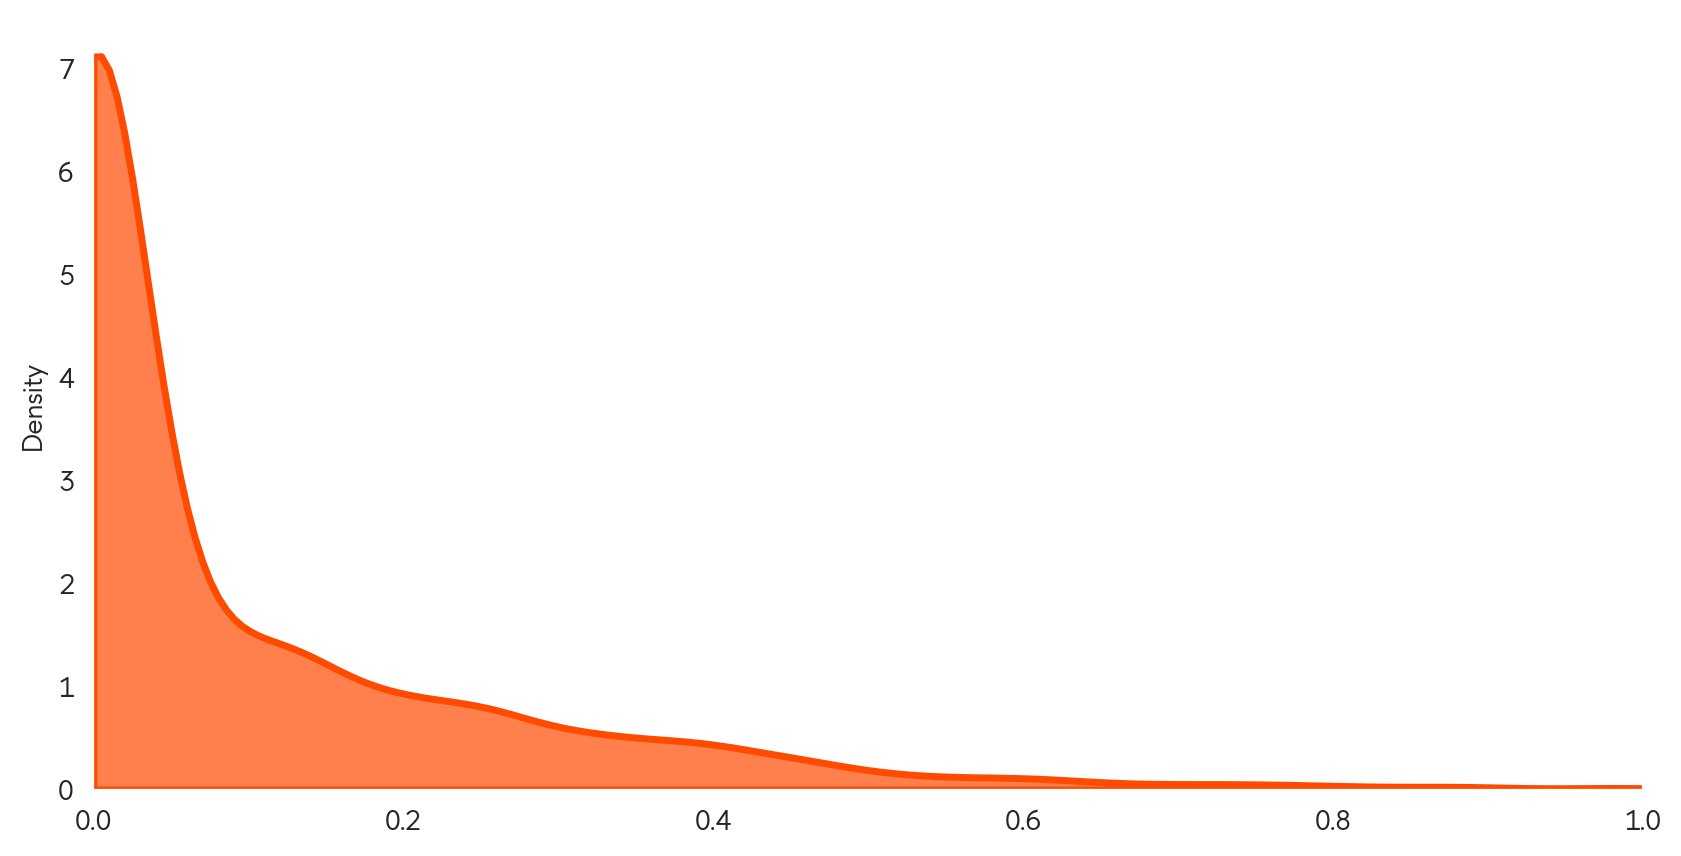

findfont: Font family 'bold' not found.
findfont: Font family 'bold' not found.
findfont: Font family 'bold' not found.
findfont: Font family 'bold' not found.
findfont: Font family 'bold' not found.


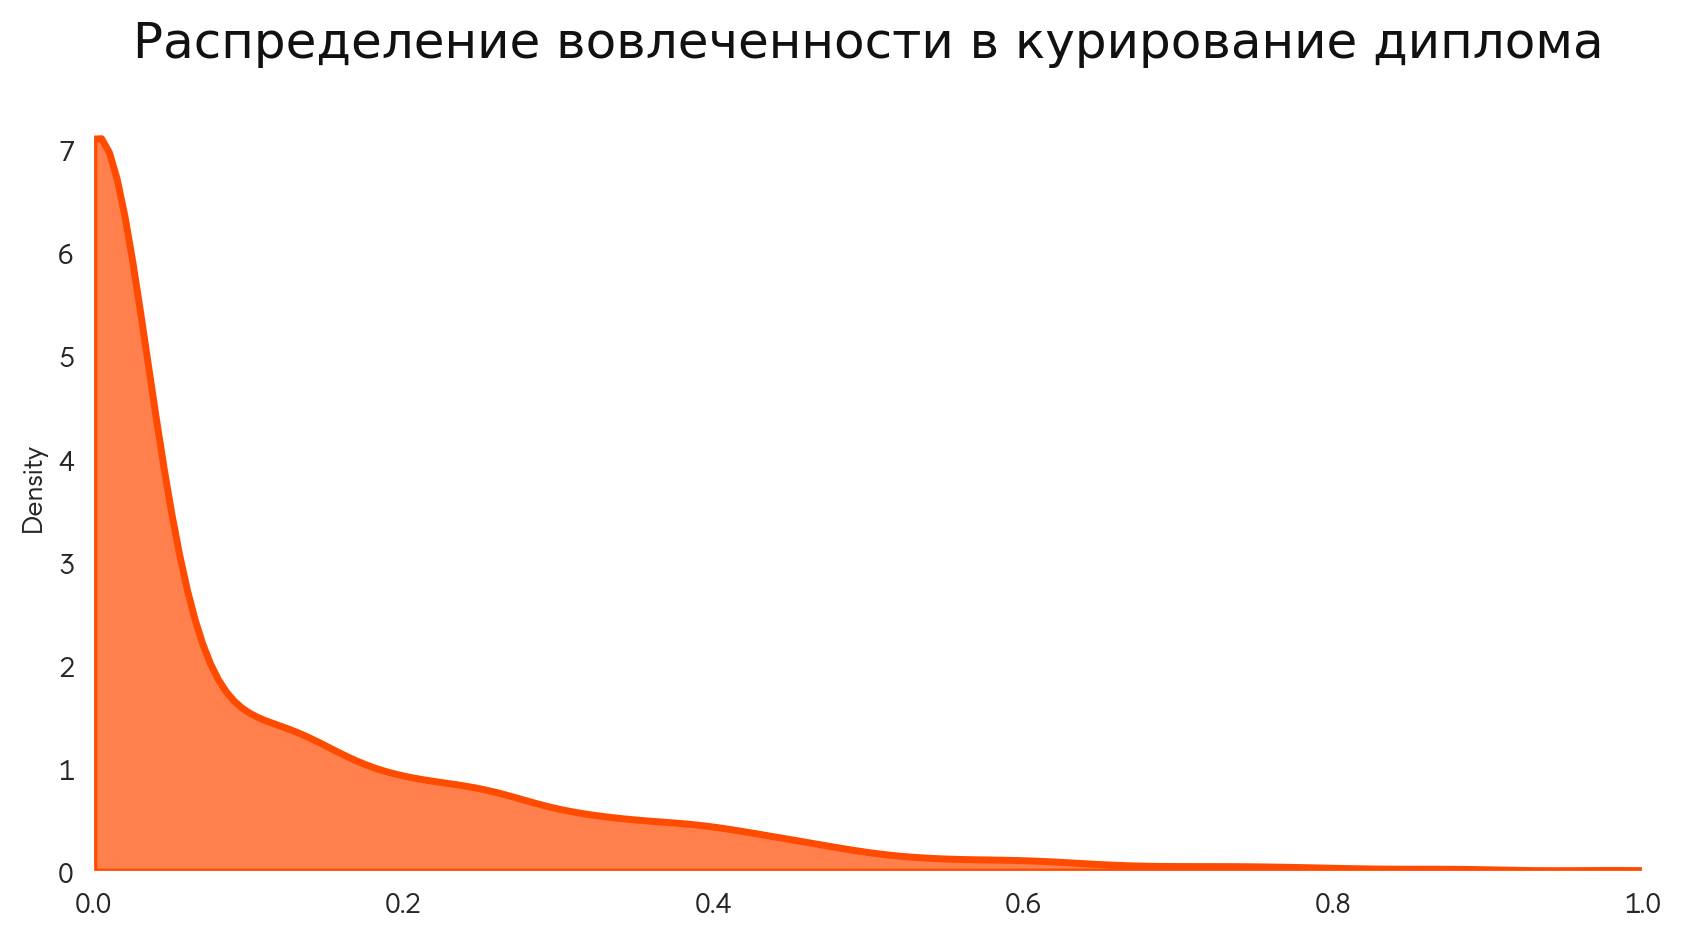

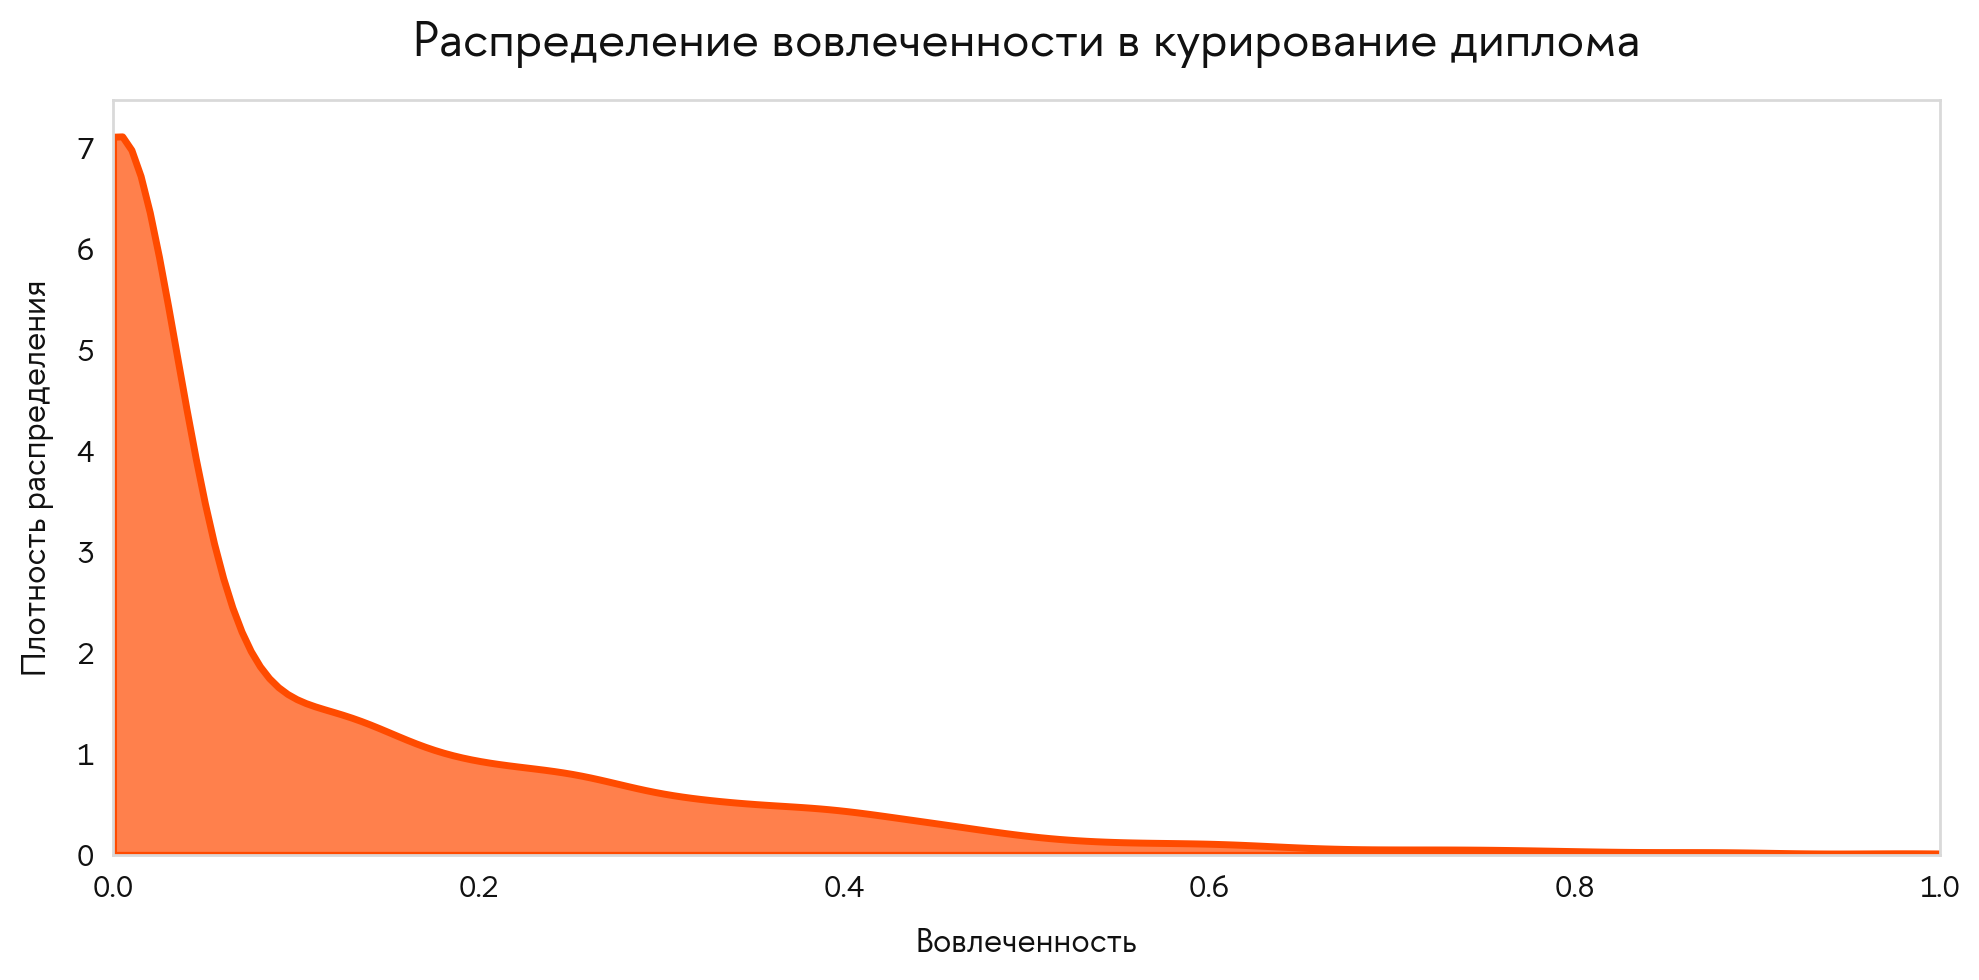

In [59]:
def plot_engagement_kde(
        s,
        title="Распределение вовлеченности в курирование диплома",
        xlabel="Вовлеченность",
        ylabel="Плотность распределения",
        filename=None,
        bw_method="scott",
        x_min=0.0,           # нижняя граница поддержки
        x_max=None           # верхняя (если None — берем по данным)
):
    s = pd.Series(s).dropna().astype(float)
    if x_max is None:
        x_max = float(s.max())

    fig, ax = plt.subplots(figsize=(10, 5), dpi=200)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    sns.kdeplot(
        x=s.values,
        fill=True,
        color=ORANGE,
        linewidth=2.5,
        alpha=0.7,
        bw_method=bw_method,
        cut=0,
        clip=(x_min, x_max),
        ax=ax
    )

    ax.set_xlim(x_min, x_max)
    ax.set_title(title, fontsize=18, color=BLACK, pad=16)
    ax.set_xlabel(xlabel, fontsize=12, color=BLACK, labelpad=8)
    ax.set_ylabel(ylabel, fontsize=12, color=BLACK, labelpad=8)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(GRAY_BORDER)
        spine.set_linewidth(1)

    ax.tick_params(axis='both', labelsize=11, colors=BLACK)
    ax.grid(False)

    plt.tight_layout()
    if filename:
        plt.savefig(filename, bbox_inches="tight", dpi=200, facecolor="white")
    plt.show()

# ===== Пример вызова =====
plot_engagement_kde(df_cleared['supervision_factor_0_1'], filename = "Waiwaiwai_chto_za_grafik.png")

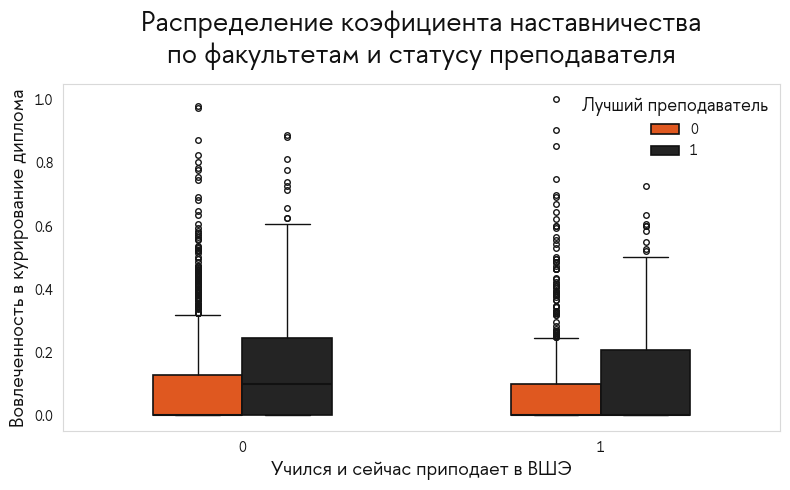

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

# === Цвета и стиль ===
ORANGE = "#ff4b00"      # яркий оранжевый
BLUE = ("#242424")        # насыщенный синий для контраста
BLACK = "#111111"
GRAY_BORDER = "#D9D9D9"

# === Boxplot ===
fig, ax = plt.subplots(figsize=(8, 5), dpi=100, facecolor="white")

sns.boxplot(
    data=df_cleared,
    x="HSE_graduate",                # инбрид
    y="supervision_factor_0_1", # ось Y
    hue="best_teacher",         # цвет по признаку награды
    palette={0: ORANGE, 1: BLUE},
    width=0.5,
    linewidth=1.3,
    fliersize=4,
    boxprops=dict(edgecolor=BLACK, linewidth=1.2),
    medianprops=dict(color=BLACK, linewidth=1.5),
    whiskerprops=dict(color=BLACK, linewidth=1.0),
    capprops=dict(color=BLACK, linewidth=1.0),
    ax=ax
)

# --- Оформление ---
ax.set_facecolor("white")
for spine in ax.spines.values():
    spine.set_edgecolor(GRAY_BORDER)
    spine.set_linewidth(0.8)

ax.grid(False)
ax.tick_params(colors=BLACK)
ax.set_xlabel("Учился и сейчас приподает в ВШЭ", size=14, color=BLACK)
ax.set_ylabel("Вовлеченность в курирование диплома", size=14, color=BLACK)
ax.set_title("Распределение коэфициента наставничества\nпо факультетам и статусу преподавателя", size=20, color=BLACK, pad=15)

leg = ax.legend(title="Лучший преподаватель", frameon=False)
plt.setp(leg.get_title(), size=13, color=BLACK)
for txt in leg.get_texts():
    txt.set_color(BLACK)

plt.tight_layout()
plt.savefig("boxplot_faculty_bestteacher.png", bbox_inches="tight", dpi=300)
plt.show()


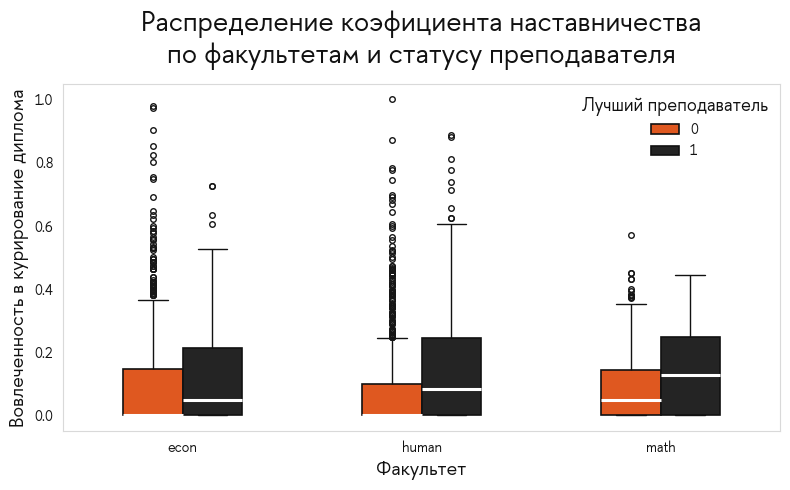

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# === Цвета и стиль ===
ORANGE = "#ff4b00"      # яркий оранжевый
BLUE = "#242424"        # насыщенный синий для контраста
BLACK = "#111111"
GRAY_BORDER = "#D9D9D9"

fig, ax = plt.subplots(figsize=(8, 5), dpi=100, facecolor="white")

sns.boxplot(
    data=df_cleared,
    x="faculty",                # факультеты
    y="supervision_factor_0_1", # ось Y
    hue="best_teacher",         # цвет по признаку награды
    palette={0: ORANGE, 1: BLUE},
    width=0.5,
    linewidth=1.3,
    fliersize=4,
    boxprops=dict(edgecolor=BLACK, linewidth=1.2),
    medianprops=dict(color="white", linewidth=2.2),  # белая медиана
    whiskerprops=dict(color=BLACK, linewidth=1.0),
    capprops=dict(color=BLACK, linewidth=1.0),
    ax=ax
)

# --- Оформление ---
ax.set_facecolor("white")
for spine in ax.spines.values():
    spine.set_edgecolor(GRAY_BORDER)
    spine.set_linewidth(0.8)

ax.grid(False)
ax.tick_params(colors=BLACK)
ax.set_xlabel("Факультет", size=14, color=BLACK)
ax.set_ylabel("Вовлеченность в курирование диплома", size=14, color=BLACK)
ax.set_title("Распределение коэфициента наставничества\nпо факультетам и статусу преподавателя", size=20, color=BLACK, pad=15)

# Легенда
leg = ax.legend(title="Лучший преподаватель", frameon=False)
plt.setp(leg.get_title(), size=13, color=BLACK)
for txt in leg.get_texts():
    txt.set_color(BLACK)

plt.tight_layout()
plt.savefig("boxplot_faculty_bestteacher_white_median.png", bbox_inches="tight", dpi=300)
plt.show()


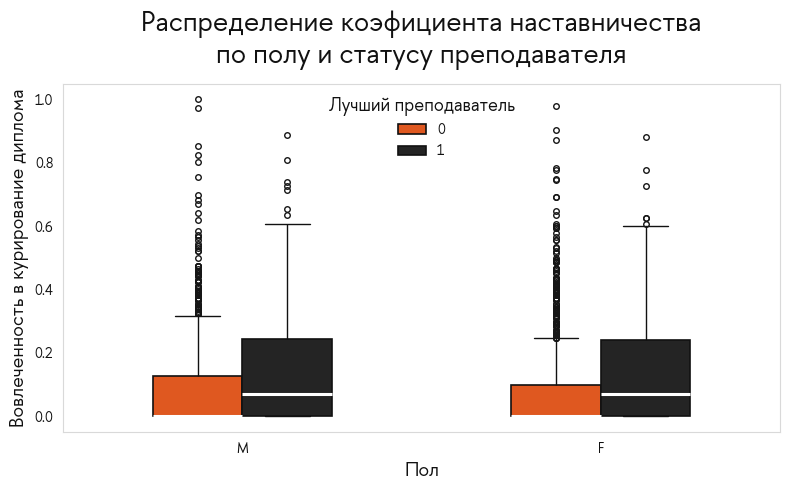

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

# === Цвета и стиль ===
ORANGE = "#ff4b00"      # яркий оранжевый
BLUE = "#242424"        # насыщенный синий для контраста
BLACK = "#111111"
GRAY_BORDER = "#D9D9D9"

# === Boxplot ===
fig, ax = plt.subplots(figsize=(8, 5), dpi=100, facecolor="white")

sns.boxplot(
    data=df_cleared,
    x="gender",                # факультеты
    y="supervision_factor_0_1", # ось Y
    hue="best_teacher",         # цвет по признаку награды
    palette={0: ORANGE, 1: BLUE},
    width=0.5,
    linewidth=1.3,
    fliersize=4,
    boxprops=dict(edgecolor=BLACK, linewidth=1.2),
    medianprops=dict(color="white", linewidth=2.2),  # белая медиана
    whiskerprops=dict(color=BLACK, linewidth=1.0),
    capprops=dict(color=BLACK, linewidth=1.0),
    ax=ax
)

# --- Оформление ---
ax.set_facecolor("white")
for spine in ax.spines.values():
    spine.set_edgecolor(GRAY_BORDER)
    spine.set_linewidth(0.8)

ax.grid(False)
ax.tick_params(colors=BLACK)
ax.set_xlabel("Пол", size=14, color=BLACK)
ax.set_ylabel("Вовлеченность в курирование диплома", size=14, color=BLACK)
ax.set_title("Распределение коэфициента наставничества\nпо полу и статусу преподавателя", size=20, color=BLACK, pad=15)

# Легенда
leg = ax.legend(title="Лучший преподаватель", frameon=False)
plt.setp(leg.get_title(), size=13, color=BLACK)
for txt in leg.get_texts():
    txt.set_color(BLACK)

plt.tight_layout()
plt.savefig("boxplot_faculty_bestteacher_white_median.png", bbox_inches="tight", dpi=300)
plt.show()
